## Import Statements

In [ ]:
import pandas as pd

import matplotlib.pyplot as plt


from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc, roc_auc_score, accuracy_score, classification_report, confusion_matrix, recall_score, precision_score

from xgboost import XGBClassifier



## placeholder data set
from sklearn.datasets import load_breast_cancer

## Load Data

In [ ]:
data = load_breast_cancer() # PLACEHOLDER DATA

## Data Exploration

In [3]:
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')

print(X.head())
print(y.value_counts())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

## Data Cleanup

VERY IMPORTANT: Make sure you do REMOVE any "leaky features". That is, variables that would leak the outcome you're trying to predict. This can include:
- DMFT
- Number of new cavities this year → directly tells the model the outcome

## Train Test Split
We will do a 70-30 split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, 
                                                    y, 
                                                    test_size=0.3, 
                                                    random_state=42)

## Logistic Regression Model

We use a logistic regression model to use as a baseline for our other models: Random Forest and XGBoost.

Logistic regression models are used to predict binary probabilities (yes/no).

In [5]:
log_pipe = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=1000))])

log_param_grid = {
    'model__C': [0.01, 0.1, 1, 10]
}

log_grid = GridSearchCV(
    log_pipe,
    log_param_grid,
    cv=5,
    scoring='roc_auc'
)
log_grid.fit(X_train, y_train)

y_pred_log = log_grid.predict(X_test)
y_proba_log = log_grid.predict_proba(X_test)[:,1]

print("Best params:", log_grid.best_params_)
print("Best CV score:", log_grid.best_score_)

Best params: {'model__C': 1}
Best CV score: 0.9928839784189538


## Random Forest Model

In [6]:
rf_model = RandomForestClassifier(random_state=42)

rf_param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [None, 5, 10, 20],
    'min_samples_leaf': [1, 5, 10]
}

rf_grid = GridSearchCV(
    rf_model,
    rf_param_grid,
    cv=5,
    scoring='roc_auc'
)
rf_grid.fit(X_train, y_train)

y_pred_rf = rf_grid.predict(X_test)
y_proba_rf = rf_grid.predict_proba(X_test)[:,1]

print("Best params:", rf_grid.best_params_)
print("Best CV score:", rf_grid.best_score_)

Best params: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}
Best CV score: 0.9892886699507389


## XGBoost Model

In [7]:
xgb_model = XGBClassifier(eval_metric='logloss', random_state=42)

xgb_param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'min_child_weight': [1, 5, 10]
}

xgb_grid = GridSearchCV(
    xgb_model,
    xgb_param_grid,
    cv=5,
    scoring='roc_auc'
)
xgb_grid.fit(X_train, y_train)

print("XGBOOST")
print("Best params:", xgb_grid.best_params_)
print("Best CV AUC:", xgb_grid.best_score_)

y_pred_xgb = xgb_grid.predict(X_test)
y_proba_xgb = xgb_grid.predict_proba(X_test)[:,1]
print("Test ROC-AUC:", roc_auc_score(y_test, y_proba_xgb))
print(classification_report(y_test, y_pred_xgb))

XGBOOST
Best params: {'learning_rate': 0.1, 'max_depth': 5, 'min_child_weight': 1, 'n_estimators': 500}
Best CV AUC: 0.9904277738681679
Test ROC-AUC: 0.9945620223398002
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        63
           1       0.98      0.98      0.98       108

    accuracy                           0.98       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.98      0.98      0.98       171



## Compare Models

Now we compare the three models (Logistic Regression, Random Forest, XGBoost) based on their scores

In [8]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Best CV AUC': [
        log_grid.best_score_,
        rf_grid.best_score_,
        xgb_grid.best_score_
    ],
    'Test ROC-AUC': [
        roc_auc_score(y_test, y_proba_log),
        roc_auc_score(y_test, y_proba_rf),
        roc_auc_score(y_test, y_proba_xgb)
    ],
    'Test Accuracy': [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ]
})

print(results)



                 Model  Best CV AUC  Test ROC-AUC  Test Accuracy
0  Logistic Regression     0.992884      0.997942       0.982456
1        Random Forest     0.989289      0.997061       0.970760
2              XGBoost     0.990428      0.994562       0.976608


### Figures

ROC curve fo each model in separate graphs:

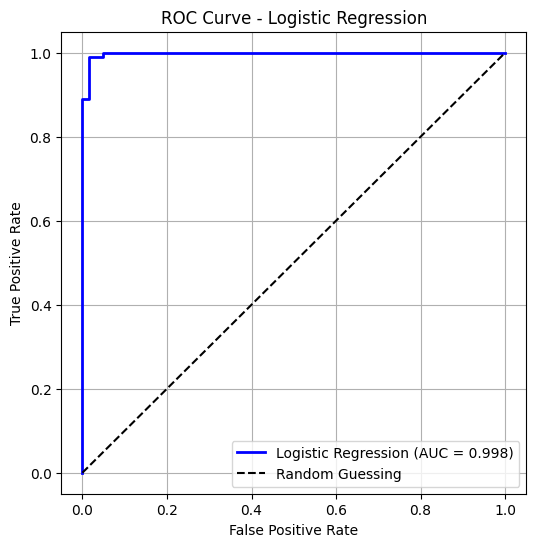

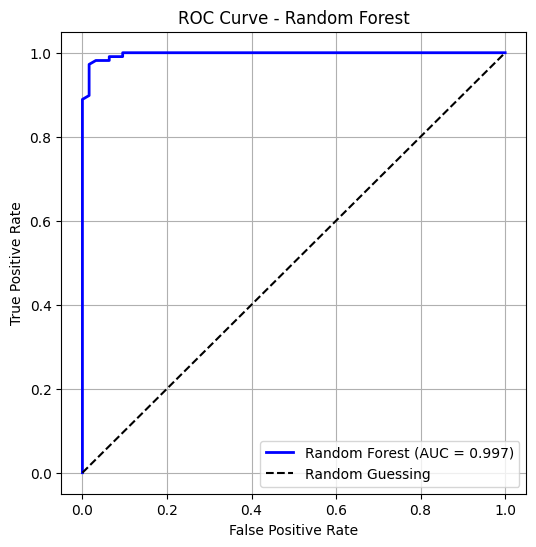

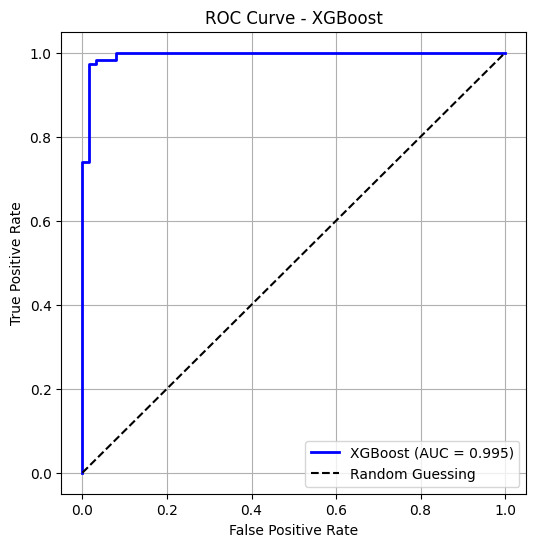

In [9]:
def plot_single_roc(y_true, y_proba, model_name):
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    auc_score = roc_auc_score(y_true, y_proba)
    
    plt.figure(figsize=(6,6))
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {auc_score:.3f})', color='blue', linewidth=2)
    plt.plot([0,1], [0,1], 'k--', label='Random Guessing')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {model_name}')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()

# --- Plot each model separately ---
plot_single_roc(y_test, y_proba_log, 'Logistic Regression')
plot_single_roc(y_test, y_proba_rf, 'Random Forest')
plot_single_roc(y_test, y_proba_xgb, 'XGBoost')

ROC curve of each model in one graph:

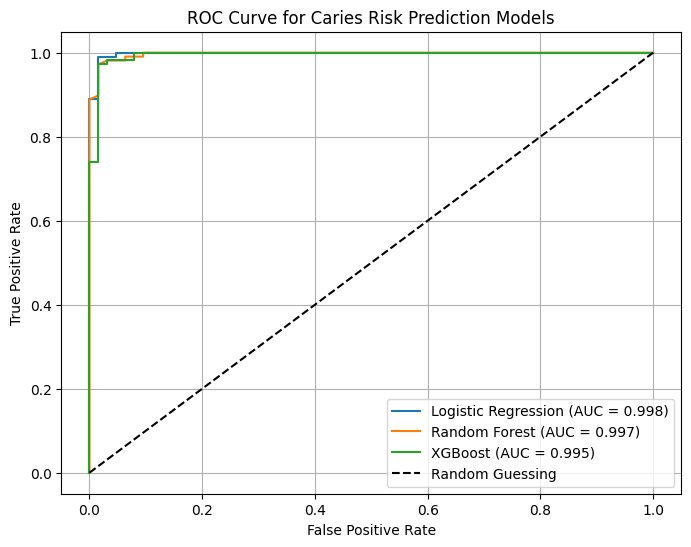

In [10]:
# Compute ROC curve for each model
fpr_log, tpr_log, _ = roc_curve(y_test, y_proba_log)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_proba_xgb)

# Compute AUCs (just to display in legend)
auc_log = roc_auc_score(y_test, y_proba_log)
auc_rf = roc_auc_score(y_test, y_proba_rf)
auc_xgb = roc_auc_score(y_test, y_proba_xgb)

# Plot
plt.figure(figsize=(8,6))
plt.plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC = {auc_log:.3f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})')
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {auc_xgb:.3f})')
plt.plot([0,1], [0,1], 'k--', label='Random Guessing')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Caries Risk Prediction Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()
